# Etapa 2 | Modelagem e Avaliação

Nesta etapa, vamos comparar o baseline de Regressão Logística desenvolvido na Etapa 1 com os modelos Random Forest e MLPClassifier, buscando identificar a melhor opção para prever o churn dos clientes.

Vamos manter o mesmo protocolo de avaliação, com divisão estratificada de 80% para treino e 20% para teste, validação cruzada de 5 folds e seed 42. A PR-AUC será nossa métrica principal, acompanhada de precision, recall, F1 e ROC-AUC.

A escolha do modelo final será baseada nos resultados da validação cruzada, considerando também a estabilidade e a capacidade de generalização.

Para manter a consistência com a Etapa 1, vamos reutilizar as variáveis, os tratamentos e o protocolo definidos pelos colegas. Algumas operações de preparação dos dados serão repetidas apenas para permitir a execução independente deste notebook, sem refazer a análise exploratória.


In [1]:
# Célula 1 - Importação das bibliotecas

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline

In [2]:
# Célula 2 - Carregamento da base tratada na Etapa 1

from pathlib import Path

# Procura o arquivo nas possíveis pastas de execução
caminhos = [
    Path("artefatos/telco_tratado.csv"),
    Path("notebooks/artefatos/telco_tratado.csv")
]

arquivo = next((p for p in caminhos if p.is_file()), None)

if arquivo is None:
    raise FileNotFoundError("Base tratada não encontrada.")

# Carrega os dados e confere as primeiras linhas
df = pd.read_csv(arquivo)

print("Arquivo:", arquivo)
print("Dimensões:", df.shape)
display(df.head())

Arquivo: artefatos\telco_tratado.csv
Dimensões: (7043, 20)


,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,1
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,1
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,1


In [3]:
# Célula 3 - Separação das variáveis de entrada e do alvo

X = df.drop(columns=["Churn Value"])
y = df["Churn Value"]

# Organiza a distribuição do alvo em tabela
tabela_alvo = pd.DataFrame({
    "Classe": ["0 - Permaneceram", "1 - Cancelaram"],
    "Clientes": [
        (y == 0).sum(),
        (y == 1).sum()
    ],
    "Proporção": [
        (y == 0).mean(),
        (y == 1).mean()
    ]
})

# Apresenta os resultados formatados
display(
    tabela_alvo.style
    .format({
        "Clientes": "{:,.0f}",
        "Proporção": "{:.2%}"
    })
    .hide(axis="index")
)

Classe,Clientes,Proporção
0 - Permaneceram,"5,174",73.46%
1 - Cancelaram,"1,869",26.54%


In [4]:
# Célula 4 - Divisão dos dados em treino e teste

from sklearn.model_selection import train_test_split

# Mantém a proporção das classes e a mesma seed da Etapa 1
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Apresenta as dimensões e a proporção de churn em tabela
tabela_divisao = pd.DataFrame({
    "Conjunto": ["Treino", "Teste"],
    "Registros": [len(X_train), len(X_test)],
    "Variáveis": [X_train.shape[1], X_test.shape[1]],
    "Proporção de churn": [y_train.mean(), y_test.mean()]
})

display(
    tabela_divisao.style
    .format({"Proporção de churn": "{:.2%}"})
    .hide(axis="index")
)

Conjunto,Registros,Variáveis,Proporção de churn
Treino,5634,19,26.54%
Teste,1409,19,26.54%


In [5]:
# Célula 5 - Identificação das variáveis numéricas e categóricas

numericas = ["Tenure Months", "Monthly Charges", "Total Charges"]
categoricas = [coluna for coluna in X.columns if coluna not in numericas]

# Apresenta a quantidade de variáveis em tabela
tabela_variaveis = pd.DataFrame({
    "Tipo de variável": [
        "Numéricas",
        "Categóricas",
        "Total"
    ],
    "Quantidade": [
        len(numericas),
        len(categoricas),
        len(numericas) + len(categoricas)
    ]
})

display(
    tabela_variaveis.style
    .hide(axis="index")
)


Tipo de variável,Quantidade
Numéricas,3
Categóricas,16
Total,19


In [6]:
# Célula 6 - Pré-processamento das variáveis

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Reutiliza as configurações definidas na Etapa 1
def criar_preprocessador():
    return ColumnTransformer(
        transformers=[
            ("num", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]), numericas),

            ("cat", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(
                    handle_unknown="ignore",
                    drop="if_binary"
                ))
            ]), categoricas)
        ],
        remainder="drop"
    )

# Monta o pipeline com o modelo escolhido
def montar_pipeline(modelo):
    return Pipeline([
        ("prep", criar_preprocessador()),
        ("modelo", modelo)
    ])

print("Pré-processamento configurado.")

Pré-processamento configurado.


In [7]:
# Célula 7 - Configuração da validação cruzada e Random Forest

# Define os 5 folds estratificados para avaliação
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Configura o modelo Random Forest
modelo_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Integra o modelo ao pré-processamento da Etapa 1
pipeline_rf = montar_pipeline(modelo_rf)

print("Validação cruzada e pipeline Random Forest configurados.")

Validação cruzada e pipeline Random Forest configurados.


In [8]:
# Célula 8 - Avaliação inicial da Random Forest

# Define as métricas utilizadas na comparação
metricas = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "recall": "recall",
    "precision": "precision",
    "f1": "f1"
}

# Executa a validação cruzada no conjunto de treino
resultados_rf = cross_validate(
    pipeline_rf,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas,
    return_train_score=True,
    n_jobs=-1
)

# Apresenta as métricas de treino e validação em tabela
tabela_rf = pd.DataFrame({
    "Métrica": list(metricas.keys()),
    "Treino": [
        resultados_rf[f"train_{m}"].mean()
        for m in metricas
    ],
    "Validação": [
        resultados_rf[f"test_{m}"].mean()
        for m in metricas
    ]
})

display(
    tabela_rf.style
    .format(precision=4)
    .hide(axis="index")
)

Métrica,Treino,Validação
pr_auc,0.9998,0.6299
roc_auc,0.9999,0.8361
recall,0.9962,0.5077
precision,0.9975,0.6432
f1,0.9968,0.5673


### Ajuste da Random Forest

Na primeira avaliação, identificamos um overfitting significativo. A PR-AUC foi de 0,9998 no treino e 0,6299 na validação, ficando abaixo do baseline de Regressão Logística (0,679).

Vamos ajustar a profundidade das árvores e o número mínimo de amostras por folha para tentar reduzir o overfitting. Depois, vamos comparar os resultados e verificar se o modelo apresentou melhora na validação.

In [9]:
# Célula 9 - Ajuste da Random Forest para reduzir o overfitting

# Limita a complexidade das árvores
modelo_rf_ajustado = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Monta o pipeline com o mesmo pré-processamento
pipeline_rf_ajustado = montar_pipeline(modelo_rf_ajustado)

# Avalia o modelo usando os mesmos folds
resultados_rf_ajustado = cross_validate(
    pipeline_rf_ajustado,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas,
    return_train_score=True,
    n_jobs=-1
)

# Compara treino e validação
for metrica in metricas:
    media_treino = resultados_rf_ajustado[f"train_{metrica}"].mean()
    media_validacao = resultados_rf_ajustado[f"test_{metrica}"].mean()

    tabela_rf_ajustada = pd.DataFrame({
    "Métrica": list(metricas.keys()),
    "Treino": [
        resultados_rf_ajustado[f"train_{m}"].mean()
        for m in metricas
    ],
    "Validação": [
        resultados_rf_ajustado[f"test_{m}"].mean()
        for m in metricas
    ]
})

display(
    tabela_rf_ajustada.style
    .format(precision=4)
    .hide(axis="index")
)

Métrica,Treino,Validação
pr_auc,0.7633,0.6811
roc_auc,0.9049,0.8591
recall,0.5963,0.5405
precision,0.7330,0.6811
f1,0.6575,0.6026


In [10]:
# Célula 10 - Segundo ajuste da Random Forest

# Aumenta o número mínimo de amostras por folha
modelo_rf_ajuste2 = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

# Monta o pipeline e executa a validação cruzada
pipeline_rf_ajuste2 = montar_pipeline(modelo_rf_ajuste2)

resultados_rf_ajuste2 = cross_validate(
    pipeline_rf_ajuste2,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas,
    return_train_score=True,
    n_jobs=-1
)

# Compara treino e validação
for metrica in metricas:
    media_treino = resultados_rf_ajuste2[f"train_{metrica}"].mean()
    media_validacao = resultados_rf_ajuste2[f"test_{metrica}"].mean()

    tabela_rf_ajuste2 = pd.DataFrame({
    "Métrica": list(metricas.keys()),
    "Treino": [
        resultados_rf_ajuste2[f"train_{m}"].mean()
        for m in metricas
    ],
    "Validação": [
        resultados_rf_ajuste2[f"test_{m}"].mean()
        for m in metricas
    ]
})

display(
    tabela_rf_ajuste2.style
    .format(precision=4)
    .hide(axis="index")
)

Métrica,Treino,Validação
pr_auc,0.7489,0.6827
roc_auc,0.8954,0.8595
recall,0.5734,0.5237
precision,0.7296,0.6828
f1,0.6420,0.5925



### Resultado do segundo ajuste

No segundo ajuste, aumentamos o número mínimo de amostras por folha de 5 para 10. A PR-AUC de validação passou de 0,6811 para 0,6827, enquanto o Recall e o F1 apresentaram uma pequena redução.
A diferença entre treino e validação também diminuiu, indicando menor overfitting. Como a PR-AUC é nossa métrica principal, vamos manter essa configuração como a melhor Random Forest até o momento.




### Otimização de hiperparâmetros da Random Forest

Depois dos ajustes manuais, vamos utilizar o GridSearchCV para testar outras combinações de hiperparâmetros e verificar se conseguimos melhorar a PR-AUC de validação.

A busca será feita com os mesmos 5 folds e apenas com os dados de treino, mantendo o conjunto de teste reservado para a avaliação final.



In [11]:
# Célula 11 - Otimização de hiperparâmetros da Random Forest

from sklearn.model_selection import GridSearchCV

# Define os hiperparâmetros que serão testados
parametros_rf = {
    "modelo__max_depth": [6, 8, 10],
    "modelo__min_samples_leaf": [5, 10, 15],
    "modelo__max_features": ["sqrt", 0.5]
}

# Configura a busca com PR-AUC e validação cruzada
grid_rf = GridSearchCV(
    estimator=montar_pipeline(
        RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=1
        )
    ),
    param_grid=parametros_rf,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

# Executa a busca somente com os dados de treino
grid_rf.fit(X_train, y_train)

# Apresenta a melhor configuração encontrada

tabela_melhor_rf = pd.DataFrame({
    "Hiperparâmetro": [
        "Profundidade máxima (max_depth)",
        "Amostras mínimas por folha (min_samples_leaf)",
        "Variáveis por divisão (max_features)",
        "PR-AUC média de validação"
    ],
    "Melhor resultado": [
        grid_rf.best_params_["modelo__max_depth"],
        grid_rf.best_params_["modelo__min_samples_leaf"],
        grid_rf.best_params_["modelo__max_features"],
        f"{grid_rf.best_score_:.4f}"
    ]
})

display(
    tabela_melhor_rf.style
    .hide(axis="index")
    .set_properties(**{
        "padding": "9px 14px",
        "border-bottom": "1px solid #555"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("text-align", "left"),
                ("padding", "10px 14px"),
                ("border-bottom", "2px solid #777")
            ]
        },
        {
            "selector": "tr:last-child td",
            "props": [
                ("background-color", "#254B3D"),
                ("color", "white"),
                ("font-weight", "bold")
            ]
        }
    ])
)

Hiperparâmetro,Melhor resultado
Profundidade máxima (max_depth),6
Amostras mínimas por folha (min_samples_leaf),10
Variáveis por divisão (max_features),0.500000
PR-AUC média de validação,0.6862


In [12]:
# Célula 12 - Avaliação do GridSearchCV

# Recupera os resultados da melhor configuração
resultados_grid = pd.DataFrame(grid_rf.cv_results_)
melhor_grid = resultados_grid.loc[grid_rf.best_index_]

# Organiza a comparação entre treino e validação
tabela_grid = pd.DataFrame({
    "Métrica": ["PR-AUC"],
    "Treino": [melhor_grid["mean_train_score"]],
    "Validação": [melhor_grid["mean_test_score"]]
})

display(
    tabela_grid.style
    .format({"Treino": "{:.4f}", "Validação": "{:.4f}"})
    .hide(axis="index")
)

Métrica,Treino,Validação
PR-AUC,0.7350,0.6862



### Otimização com RandomizedSearchCV

Após o GridSearchCV, vamos explorar um espaço maior de hiperparâmetros com o RandomizedSearchCV, incluindo diferentes profundidades, quantidades mínimas de amostras e proporções de variáveis por divisão.

Manteremos a PR-AUC como métrica principal e os mesmos cinco folds de validação cruzada, utilizando apenas o conjunto de treino. Depois, compararemos os resultados das duas buscas e dos ajustes manuais.


In [13]:
# Célula 13 - Otimização com RandomizedSearchCV

from sklearn.model_selection import RandomizedSearchCV

# Define o espaço de busca dos hiperparâmetros
parametros_random_rf = {
    "modelo__max_depth": [4, 5, 6, 7, 8, 9, 10, 12],
    "modelo__min_samples_leaf": [3, 5, 8, 10, 12, 15, 20],
    "modelo__min_samples_split": [2, 5, 10, 15, 20],
    "modelo__max_features": ["sqrt", 0.3, 0.5, 0.7]
}

# Configura a busca aleatória com validação cruzada
random_rf = RandomizedSearchCV(
    estimator=montar_pipeline(
        RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=1
        )
    ),
    param_distributions=parametros_random_rf,
    n_iter=30,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

# Executa a busca somente com os dados de treino
random_rf.fit(X_train, y_train)

# Organiza a melhor configuração encontrada
tabela_random_rf = pd.DataFrame({
    "Hiperparâmetro": [
        "Profundidade máxima (max_depth)",
        "Amostras mínimas por folha (min_samples_leaf)",
        "Amostras mínimas por divisão (min_samples_split)",
        "Variáveis por divisão (max_features)",
        "PR-AUC média de validação"
    ],
    "Melhor resultado": [
        random_rf.best_params_["modelo__max_depth"],
        random_rf.best_params_["modelo__min_samples_leaf"],
        random_rf.best_params_["modelo__min_samples_split"],
        random_rf.best_params_["modelo__max_features"],
        f"{random_rf.best_score_:.4f}"
    ]
})

display(
    tabela_random_rf.style
    .hide(axis="index")
    .set_properties(**{
        "padding": "9px 14px",
        "border-bottom": "1px solid #555"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("text-align", "left"),
                ("padding", "10px 14px"),
                ("border-bottom", "2px solid #777")
            ]
        },
        {
            "selector": "tr:last-child td",
            "props": [
                ("background-color", "#254B3D"),
                ("color", "white"),
                ("font-weight", "bold")
            ]
        }
    ])
)

Hiperparâmetro,Melhor resultado
Profundidade máxima (max_depth),8
Amostras mínimas por folha (min_samples_leaf),15
Amostras mínimas por divisão (min_samples_split),2
Variáveis por divisão (max_features),0.300000
PR-AUC média de validação,0.6861


In [14]:
# Célula 14 - Avaliação do RandomizedSearchCV

# Recupera os resultados da melhor configuração
resultados_random = pd.DataFrame(random_rf.cv_results_)
melhor_random = resultados_random.loc[random_rf.best_index_]

# Organiza a comparação entre treino e validação
tabela_random = pd.DataFrame({
    "Métrica": ["PR-AUC"],
    "Treino": [melhor_random["mean_train_score"]],
    "Validação": [melhor_random["mean_test_score"]]
})

display(
    tabela_random.style
    .format({"Treino": "{:.4f}", "Validação": "{:.4f}"})
    .hide(axis="index")
)

Métrica,Treino,Validação
PR-AUC,0.7570,0.6861


In [15]:
# Célula 15 - Avaliação das configurações otimizadas

# Reavalia as configurações selecionadas nas duas buscas
resultados_grid_completo = cross_validate(
    grid_rf.best_estimator_,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas,
    return_train_score=True,
    n_jobs=-1
)

resultados_random_completo = cross_validate(
    random_rf.best_estimator_,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas,
    return_train_score=True,
    n_jobs=-1
)

# Organiza os resultados de validação
tabela_otimizacoes = pd.DataFrame({
    "Métrica": ["PR-AUC", "ROC-AUC", "Recall", "Precision", "F1"],
    "GridSearchCV": [
        resultados_grid_completo[f"test_{m}"].mean()
        for m in metricas
    ],
    "RandomizedSearchCV": [
        resultados_random_completo[f"test_{m}"].mean()
        for m in metricas
    ]
})

display(
    tabela_otimizacoes.style
    .format(precision=4)
    .hide(axis="index")
    .highlight_max(
        subset=["GridSearchCV", "RandomizedSearchCV"],
        axis=1,
        props="background-color: #254B3D; color: white; font-weight: bold;"
    )
    .set_properties(**{
        "padding": "9px 14px",
        "border-bottom": "1px solid #555"
    })
)

Métrica,GridSearchCV,RandomizedSearchCV
PR-AUC,0.6862,0.6861
ROC-AUC,0.8627,0.8610
Recall,0.5445,0.5425
Precision,0.6746,0.6846
F1,0.6022,0.6049


In [16]:
# Célula 16 - Comparação geral da Random Forest

# Reúne as métricas de validação dos cinco experimentos
experimentos_rf = {
    "RF inicial": resultados_rf,
    "RF ajuste 1": resultados_rf_ajustado,
    "RF ajuste 2": resultados_rf_ajuste2,
    "GridSearchCV": resultados_grid_completo,
    "RandomizedSearchCV": resultados_random_completo
}

comparacao_rf = pd.DataFrame({
    nome: {
        metrica.upper().replace("_", "-"): resultado[f"test_{metrica}"].mean()
        for metrica in metricas
    }
    for nome, resultado in experimentos_rf.items()
})

# Apresenta a comparação com destaque para o maior valor de cada métrica
display(
    comparacao_rf.style
    .format("{:.4f}")
    .highlight_max(
        axis=1,
        props="background-color: #254B3D; color: white; font-weight: bold;"
    )
    .set_properties(**{
        "padding": "9px 14px",
        "border-bottom": "1px solid #555",
        "text-align": "center"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("padding", "10px 14px"),
                ("border-bottom", "2px solid #777")
            ]
        }
    ])
)

,RF inicial,RF ajuste 1,RF ajuste 2,GridSearchCV,RandomizedSearchCV
PR-AUC,0.6299,0.6811,0.6827,0.6862,0.6861
ROC-AUC,0.8361,0.8591,0.8595,0.8627,0.8610
RECALL,0.5077,0.5405,0.5237,0.5445,0.5425
PRECISION,0.6432,0.6811,0.6828,0.6746,0.6846
F1,0.5673,0.6026,0.5925,0.6022,0.6049


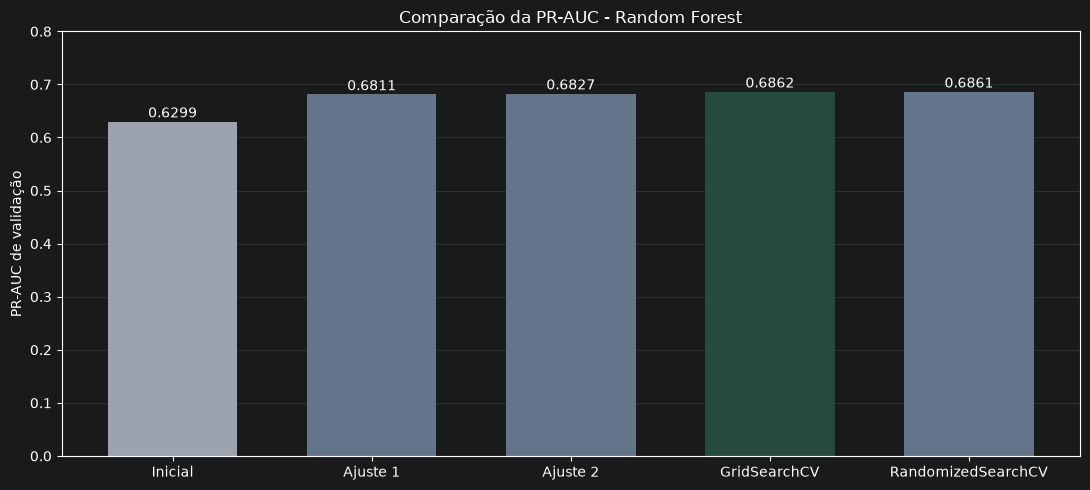

In [17]:
# Célula 17 - Gráfico comparativo da Random Forest

import matplotlib.pyplot as plt

# Recupera os resultados de PR-AUC dos cinco experimentos
valores_pr_auc = comparacao_rf.loc["PR-AUC"]
nomes = ["Inicial", "Ajuste 1", "Ajuste 2", "GridSearchCV", "RandomizedSearchCV"]

cores = ["#9CA3AF", "#64748B", "#64748B", "#254B3D", "#64748B"]

fig, ax = plt.subplots(figsize=(11, 5))

barras = ax.bar(nomes, valores_pr_auc.values, color=cores, width=0.65)

# Exibe o valor acima de cada barra
for barra, valor in zip(barras, valores_pr_auc.values):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.008,
        f"{valor:.4f}",
        ha="center",
        fontsize=10
    )

ax.set_title("Comparação da PR-AUC - Random Forest")
ax.set_ylabel("PR-AUC de validação")
ax.set_ylim(0, 0.8)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Conclusão dos experimentos com Random Forest

Começamos com uma Random Forest sem ajustes, que apresentou PR-AUC de 0,6299 na validação e uma diferença muito grande entre treino e validação, indicando overfitting.
Para tentar melhorar o resultado, fizemos dois ajustes manuais e depois utilizamos GridSearchCV e RandomizedSearchCV para testar outras combinações de hiperparâmetros.
O GridSearchCV apresentou a maior PR-AUC de validação (0,6862), enquanto o RandomizedSearchCV ficou muito próximo (0,6861) e teve resultados um pouco melhores em Precision e F1.
Como definimos a PR-AUC como nossa métrica principal, vamos manter a configuração encontrada pelo GridSearchCV como a melhor Random Forest até aqui. Ainda precisamos compará-la com os outros modelos antes de escolher o campeão.

O conjunto de teste continua reservado para a avaliação final.

In [18]:
# Célula 18 - Configuração e avaliação inicial do MLPClassifier

# Configura a rede neural com uma camada de 64 neurônios
modelo_mlp = MLPClassifier(
    hidden_layer_sizes=(64,),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    max_iter=500,
    random_state=42
)

# Integra o modelo ao pré-processamento
pipeline_mlp = montar_pipeline(modelo_mlp)

# Avalia treino e validação nos mesmos 5 folds
resultados_mlp = cross_validate(
    pipeline_mlp,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas,
    return_train_score=True,
    n_jobs=-1
)

# Apresenta os resultados médios
for metrica in metricas:
    media_treino = resultados_mlp[f"train_{metrica}"].mean()
    media_validacao = resultados_mlp[f"test_{metrica}"].mean()

    tabela_mlp = pd.DataFrame({
    "Métrica": list(metricas.keys()),
    "Treino": [
        resultados_mlp[f"train_{m}"].mean()
        for m in metricas
    ],
    "Validação": [
        resultados_mlp[f"test_{m}"].mean()
        for m in metricas
    ]
})

display(
    tabela_mlp.style
    .format(precision=4)
    .hide(axis="index")
)

Métrica,Treino,Validação
pr_auc,0.8319,0.6209
roc_auc,0.9370,0.8323
recall,0.7640,0.5940
precision,0.7561,0.5988
f1,0.7598,0.5958



### Ajuste do MLPClassifier

Na primeira avaliação, o MLPClassifier apresentou sinais de overfitting, com PR-AUC de 0,8319 no treino e 0,6209 na validação.
Vamos reduzir a quantidade de neurônios, aumentar a regularização e utilizar parada antecipada para tentar melhorar a generalização. Depois, vamos comparar os resultados com a configuração inicial.


In [19]:
# Célula 19 - Ajuste do MLPClassifier para reduzir o overfitting

# Reduz a rede e aumenta a regularização
modelo_mlp_ajustado = MLPClassifier(
    hidden_layer_sizes=(32,),
    activation="relu",
    solver="adam",
    alpha=0.01,
    early_stopping=True,
    n_iter_no_change=15,
    max_iter=500,
    random_state=42
)

# Monta o pipeline com o mesmo pré-processamento
pipeline_mlp_ajustado = montar_pipeline(modelo_mlp_ajustado)

# Executa a validação cruzada
resultados_mlp_ajustado = cross_validate(
    pipeline_mlp_ajustado,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas,
    return_train_score=True,
    n_jobs=-1
)

# Compara treino e validação
for metrica in metricas:
    media_treino = resultados_mlp_ajustado[f"train_{metrica}"].mean()
    media_validacao = resultados_mlp_ajustado[f"test_{metrica}"].mean()

    tabela_mlp_ajustado = pd.DataFrame({
    "Métrica": list(metricas.keys()),
    "Treino": [
        resultados_mlp_ajustado[f"train_{m}"].mean()
        for m in metricas
    ],
    "Validação": [
        resultados_mlp_ajustado[f"test_{m}"].mean()
        for m in metricas
    ]
})

display(
    tabela_mlp_ajustado.style
    .format(precision=4)
    .hide(axis="index")
)

Métrica,Treino,Validação
pr_auc,0.6818,0.6621
roc_auc,0.8594,0.8513
recall,0.5535,0.5492
precision,0.6856,0.6663
f1,0.6116,0.6008


In [20]:
# Célula 20 - Comparação dos experimentos do MLPClassifier

# Organiza as métricas de treino e validação
comparacao_mlp = pd.DataFrame({
    "Métrica": list(metricas.keys()),
    "Treino inicial": [
        resultados_mlp[f"train_{m}"].mean() for m in metricas
    ],
    "Validação inicial": [
        resultados_mlp[f"test_{m}"].mean() for m in metricas
    ],
    "Treino ajustado": [
        resultados_mlp_ajustado[f"train_{m}"].mean() for m in metricas
    ],
    "Validação ajustado": [
        resultados_mlp_ajustado[f"test_{m}"].mean() for m in metricas
    ]
})

# Apresenta a comparação com destaque para os melhores resultados de validação

# Apresenta a comparação com destaque para os melhores resultados

colunas_validacao = ["Validação inicial", "Validação ajustado"]
colunas_numericas = [
    "Treino inicial",
    "Validação inicial",
    "Treino ajustado",
    "Validação ajustado"
]

display(
    comparacao_mlp.style
    .format("{:.4f}", subset=colunas_numericas)
    .highlight_max(
        subset=colunas_validacao,
        axis=1,
        props="background-color: #254B3D; color: white; font-weight: bold;"
    )
    .hide(axis="index")
    .set_properties(**{
        "padding": "9px 14px",
        "border-bottom": "1px solid #555",
        "text-align": "center"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("padding", "10px 14px"),
                ("border-bottom", "2px solid #777")
            ]
        }
    ])
)

Métrica,Treino inicial,Validação inicial,Treino ajustado,Validação ajustado
pr_auc,0.8319,0.6209,0.6818,0.6621
roc_auc,0.9370,0.8323,0.8594,0.8513
recall,0.7640,0.5940,0.5535,0.5492
precision,0.7561,0.5988,0.6856,0.6663
f1,0.7598,0.5958,0.6116,0.6008


### Otimização de hiperparâmetros do MLPClassifier

Depois do primeiro ajuste, conseguimos melhorar a PR-AUC e reduzir a diferença entre treino e validação.
Agora vamos utilizar o GridSearchCV para testar outras combinações de hiperparâmetros do MLPClassifier. Vamos manter os mesmos cinco folds, a PR-AUC como métrica principal e utilizar apenas os dados de treino.

Depois vamos comparar os resultados com as configurações que já testamos.

In [21]:
# Célula 21 - GridSearchCV do MLPClassifier

# Define as combinações de hiperparâmetros
parametros_mlp = {
    "modelo__hidden_layer_sizes": [(16,), (32,), (64,)],
    "modelo__alpha": [0.001, 0.01, 0.1],
    "modelo__learning_rate_init": [0.001, 0.01]
}

# Configura a busca com validação cruzada
grid_mlp = GridSearchCV(
    estimator=montar_pipeline(
        MLPClassifier(
            activation="relu",
            solver="adam",
            early_stopping=True,
            n_iter_no_change=15,
            max_iter=500,
            random_state=42
        )
    ),
    param_grid=parametros_mlp,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

# Executa a busca apenas com os dados de treino
grid_mlp.fit(X_train, y_train)

# Organiza a melhor configuração encontrada
tabela_grid_mlp = pd.DataFrame({
    "Hiperparâmetro": [
        "Neurônios na camada oculta (hidden_layer_sizes)",
        "Regularização (alpha)",
        "Taxa de aprendizagem (learning_rate_init)",
        "PR-AUC média de validação"
    ],
    "Melhor resultado": [
        str(grid_mlp.best_params_["modelo__hidden_layer_sizes"]),
        grid_mlp.best_params_["modelo__alpha"],
        grid_mlp.best_params_["modelo__learning_rate_init"],
        f"{grid_mlp.best_score_:.4f}"
    ]
})

# Apresenta os resultados no padrão visual do notebook
display(
    tabela_grid_mlp.style
    .hide(axis="index")
    .set_properties(**{
        "padding": "9px 14px",
        "border-bottom": "1px solid #555"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("text-align", "left"),
                ("padding", "10px 14px"),
                ("border-bottom", "2px solid #777")
            ]
        },
        {
            "selector": "tr:last-child td",
            "props": [
                ("background-color", "#254B3D"),
                ("color", "white"),
                ("font-weight", "bold")
            ]
        }
    ])
)

Hiperparâmetro,Melhor resultado
Neurônios na camada oculta (hidden_layer_sizes),"(32,)"
Regularização (alpha),0.001000
Taxa de aprendizagem (learning_rate_init),0.010000
PR-AUC média de validação,0.6780


In [22]:
# Célula 22 - Avaliação do GridSearchCV do MLPClassifier

# Recupera os resultados da melhor configuração
resultados_grid_mlp = pd.DataFrame(grid_mlp.cv_results_)
melhor_grid_mlp = resultados_grid_mlp.loc[grid_mlp.best_index_]

# Organiza a comparação entre treino e validação
tabela_grid_mlp_avaliacao = pd.DataFrame({
    "Métrica": ["PR-AUC"],
    "Treino": [melhor_grid_mlp["mean_train_score"]],
    "Validação": [melhor_grid_mlp["mean_test_score"]]
})

display(
    tabela_grid_mlp_avaliacao.style
    .format("{:.4f}", subset=["Treino", "Validação"])
    .hide(axis="index")
    .set_properties(**{
        "padding": "9px 14px",
        "border-bottom": "1px solid #555"
    })
)

Métrica,Treino,Validação
PR-AUC,0.6999,0.6780


### Otimização com RandomizedSearchCV

Depois do GridSearchCV, conseguimos melhorar a PR-AUC do MLPClassifier para 0,6780, mantendo uma diferença pequena entre treino e validação.
Agora vamos utilizar o RandomizedSearchCV para testar outras combinações de hiperparâmetros e verificar se conseguimos melhorar esse resultado.

Vamos manter os mesmos cinco folds, a PR-AUC como métrica principal e utilizar apenas os dados de treino.

In [23]:
# Célula 23 - RandomizedSearchCV do MLPClassifier

from sklearn.model_selection import RandomizedSearchCV

# Define o espaço de busca dos hiperparâmetros
parametros_random_mlp = {
    "modelo__hidden_layer_sizes": [(16,), (24,), (32,), (48,), (64,), (32, 16)],
    "modelo__alpha": [0.0001, 0.001, 0.005, 0.01, 0.05, 0.1],
    "modelo__learning_rate_init": [0.0005, 0.001, 0.003, 0.005, 0.01]
}

# Configura a busca aleatória com validação cruzada
random_mlp = RandomizedSearchCV(
    estimator=montar_pipeline(
        MLPClassifier(
            activation="relu",
            solver="adam",
            early_stopping=True,
            n_iter_no_change=15,
            max_iter=500,
            random_state=42
        )
    ),
    param_distributions=parametros_random_mlp,
    n_iter=30,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

# Executa a busca somente com os dados de treino
random_mlp.fit(X_train, y_train)

# Organiza a melhor configuração encontrada
tabela_random_mlp = pd.DataFrame({
    "Hiperparâmetro": [
        "Neurônios na camada oculta (hidden_layer_sizes)",
        "Regularização (alpha)",
        "Taxa de aprendizagem (learning_rate_init)",
        "PR-AUC média de validação"
    ],
    "Melhor resultado": [
        str(random_mlp.best_params_["modelo__hidden_layer_sizes"]),
        random_mlp.best_params_["modelo__alpha"],
        random_mlp.best_params_["modelo__learning_rate_init"],
        f"{random_mlp.best_score_:.4f}"
    ]
})

# Apresenta os resultados no padrão visual do notebook
display(
    tabela_random_mlp.style
    .hide(axis="index")
    .set_properties(**{
        "padding": "9px 14px",
        "border-bottom": "1px solid #555"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("text-align", "left"),
                ("padding", "10px 14px"),
                ("border-bottom", "2px solid #777")
            ]
        },
        {
            "selector": "tr:last-child td",
            "props": [
                ("background-color", "#254B3D"),
                ("color", "white"),
                ("font-weight", "bold")
            ]
        }
    ])
)

Hiperparâmetro,Melhor resultado
Neurônios na camada oculta (hidden_layer_sizes),"(48,)"
Regularização (alpha),0.005000
Taxa de aprendizagem (learning_rate_init),0.005000
PR-AUC média de validação,0.6782


In [24]:
# Célula 24 - Avaliação do RandomizedSearchCV do MLPClassifier

# Recupera os resultados da melhor configuração
resultados_random_mlp = pd.DataFrame(random_mlp.cv_results_)
melhor_random_mlp = resultados_random_mlp.loc[random_mlp.best_index_]

# Organiza a comparação entre treino e validação
tabela_random_mlp_avaliacao = pd.DataFrame({
    "Métrica": ["PR-AUC"],
    "Treino": [melhor_random_mlp["mean_train_score"]],
    "Validação": [melhor_random_mlp["mean_test_score"]]
})

display(
    tabela_random_mlp_avaliacao.style
    .format("{:.4f}", subset=["Treino", "Validação"])
    .hide(axis="index")
    .set_properties(**{
        "padding": "9px 14px",
        "border-bottom": "1px solid #555"
    })
)

Métrica,Treino,Validação
PR-AUC,0.7113,0.6782


In [25]:
# Célula 25 - Avaliação das configurações otimizadas do MLPClassifier

# Avalia as melhores configurações das duas buscas
resultados_grid_mlp_completo = cross_validate(
    grid_mlp.best_estimator_,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas,
    return_train_score=True,
    n_jobs=-1
)

resultados_random_mlp_completo = cross_validate(
    random_mlp.best_estimator_,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas,
    return_train_score=True,
    n_jobs=-1
)

# Organiza as métricas de validação
tabela_otimizacoes_mlp = pd.DataFrame({
    "Métrica": ["PR-AUC", "ROC-AUC", "Recall", "Precision", "F1"],
    "GridSearchCV": [
        resultados_grid_mlp_completo[f"test_{m}"].mean()
        for m in metricas
    ],
    "RandomizedSearchCV": [
        resultados_random_mlp_completo[f"test_{m}"].mean()
        for m in metricas
    ]
})

# Destaca o melhor resultado de cada métrica
display(
    tabela_otimizacoes_mlp.style
    .format("{:.4f}", subset=["GridSearchCV", "RandomizedSearchCV"])
    .hide(axis="index")
    .highlight_max(
        subset=["GridSearchCV", "RandomizedSearchCV"],
        axis=1,
        props="background-color: #254B3D; color: white; font-weight: bold;"
    )
    .set_properties(**{
        "padding": "9px 14px",
        "border-bottom": "1px solid #555",
        "text-align": "center"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("padding", "10px 14px"),
                ("border-bottom", "2px solid #777")
            ]
        }
    ])
)

Métrica,GridSearchCV,RandomizedSearchCV
PR-AUC,0.6780,0.6782
ROC-AUC,0.8581,0.8587
Recall,0.5391,0.5472
Precision,0.6932,0.6849
F1,0.6045,0.6071


In [26]:
# Célula 26 - Comparação geral do MLPClassifier

# Reúne os quatro experimentos
experimentos_mlp = {
    "MLP inicial": resultados_mlp,
    "MLP ajuste 1": resultados_mlp_ajustado,
    "GridSearchCV": resultados_grid_mlp_completo,
    "RandomizedSearchCV": resultados_random_mlp_completo
}

# Organiza as métricas de validação
comparacao_mlp_final = pd.DataFrame({
    nome: {
        metrica.upper().replace("_", "-"): resultado[f"test_{metrica}"].mean()
        for metrica in metricas
    }
    for nome, resultado in experimentos_mlp.items()
})

# Destaca o maior resultado de cada métrica
display(
    comparacao_mlp_final.style
    .format("{:.4f}")
    .highlight_max(
        axis=1,
        props="background-color: #254B3D; color: white; font-weight: bold;"
    )
    .set_properties(**{
        "padding": "9px 14px",
        "border-bottom": "1px solid #555",
        "text-align": "center"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("padding", "10px 14px"),
                ("border-bottom", "2px solid #777")
            ]
        }
    ])
)

,MLP inicial,MLP ajuste 1,GridSearchCV,RandomizedSearchCV
PR-AUC,0.6209,0.6621,0.6780,0.6782
ROC-AUC,0.8323,0.8513,0.8581,0.8587
RECALL,0.5940,0.5492,0.5391,0.5472
PRECISION,0.5988,0.6663,0.6932,0.6849
F1,0.5958,0.6008,0.6045,0.6071


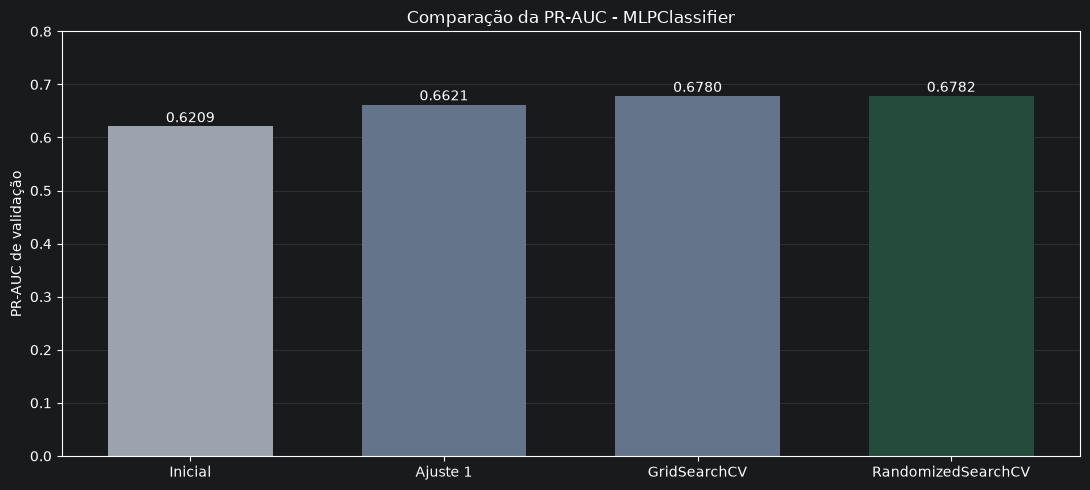

In [27]:
# Célula 27 - Gráfico comparativo do MLPClassifier

# Recupera a PR-AUC de validação dos quatro experimentos
valores_pr_auc_mlp = comparacao_mlp_final.loc["PR-AUC"]

nomes_mlp = ["Inicial", "Ajuste 1", "GridSearchCV", "RandomizedSearchCV"]
cores_mlp = ["#9CA3AF", "#64748B", "#64748B", "#254B3D"]

fig, ax = plt.subplots(figsize=(11, 5))

barras = ax.bar(nomes_mlp, valores_pr_auc_mlp.values, color=cores_mlp, width=0.65)

# Exibe o valor acima de cada barra
for barra, valor in zip(barras, valores_pr_auc_mlp.values):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.008,
        f"{valor:.4f}",
        ha="center",
        fontsize=10
    )

ax.set_title("Comparação da PR-AUC - MLPClassifier")
ax.set_ylabel("PR-AUC de validação")
ax.set_ylim(0, 0.8)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Conclusão dos experimentos com MLPClassifier

Começamos com uma configuração inicial do MLPClassifier, que apresentou PR-AUC de 0,6209 na validação e uma diferença grande entre treino e validação, indicando overfitting.

Fizemos um primeiro ajuste para reduzir esse problema e conseguimos melhorar a PR-AUC para 0,6621. Depois, utilizamos GridSearchCV e RandomizedSearchCV para testar outras combinações de hiperparâmetros.

O RandomizedSearchCV apresentou a maior PR-AUC de validação (0,6782), além dos melhores resultados de ROC-AUC e F1 entre as configurações testadas. O GridSearchCV ficou muito próximo, com PR-AUC de 0,6780 e Precision um pouco maior.

Como estamos utilizando a PR-AUC como métrica principal, vamos manter a configuração encontrada pelo RandomizedSearchCV como nossa melhor opção do MLPClassifier até aqui.

Ainda precisamos comparar esse resultado com a Regressão Logística e a Random Forest antes de escolher o modelo campeão. O conjunto de teste continua reservado.

In [28]:
# Célula 28 - Validação do baseline de Regressão Logística

from sklearn.linear_model import LogisticRegression

# Reproduz a configuração escolhida na Etapa 1
modelo_lr = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

pipeline_lr = montar_pipeline(modelo_lr)

# Avalia o baseline com o mesmo protocolo da Etapa 2
resultados_lr = cross_validate(
    pipeline_lr,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas,
    return_train_score=True,
    n_jobs=-1
)

# Organiza as métricas de validação
tabela_lr = pd.DataFrame({
    "Métrica": ["PR-AUC", "ROC-AUC", "Recall", "Precision", "F1"],
    "Regressão Logística": [
        resultados_lr[f"test_{m}"].mean()
        for m in metricas
    ]
})

display(
    tabela_lr.style
    .format("{:.4f}", subset=["Regressão Logística"])
    .hide(axis="index")
    .set_properties(**{
        "padding": "9px 14px",
        "border-bottom": "1px solid #555"
    })
)

Métrica,Regressão Logística
PR-AUC,0.6788
ROC-AUC,0.8588
Recall,0.8094
Precision,0.5294
F1,0.6398


In [29]:
# Célula 29 - Comparação dos três modelos

# Reúne os melhores modelos de cada algoritmo
modelos_finais = {
    "Regressão Logística": resultados_lr,
    "Random Forest": resultados_grid_completo,
    "MLPClassifier": resultados_random_mlp_completo
}

# Organiza as métricas médias de validação
comparacao_final = pd.DataFrame({
    nome: {
        metrica.upper().replace("_", "-"): resultado[f"test_{metrica}"].mean()
        for metrica in metricas
    }
    for nome, resultado in modelos_finais.items()
})

# Destaca o maior resultado de cada métrica
display(
    comparacao_final.style
    .format("{:.4f}")
    .highlight_max(
        axis=1,
        props="background-color: #254B3D; color: white; font-weight: bold;"
    )
    .set_properties(**{
        "padding": "9px 14px",
        "border-bottom": "1px solid #555",
        "text-align": "center"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("padding", "10px 14px"),
                ("border-bottom", "2px solid #777")
            ]
        }
    ])
)

,Regressão Logística,Random Forest,MLPClassifier
PR-AUC,0.6788,0.6862,0.6782
ROC-AUC,0.8588,0.8627,0.8587
RECALL,0.8094,0.5445,0.5472
PRECISION,0.5294,0.6746,0.6849
F1,0.6398,0.6022,0.6071


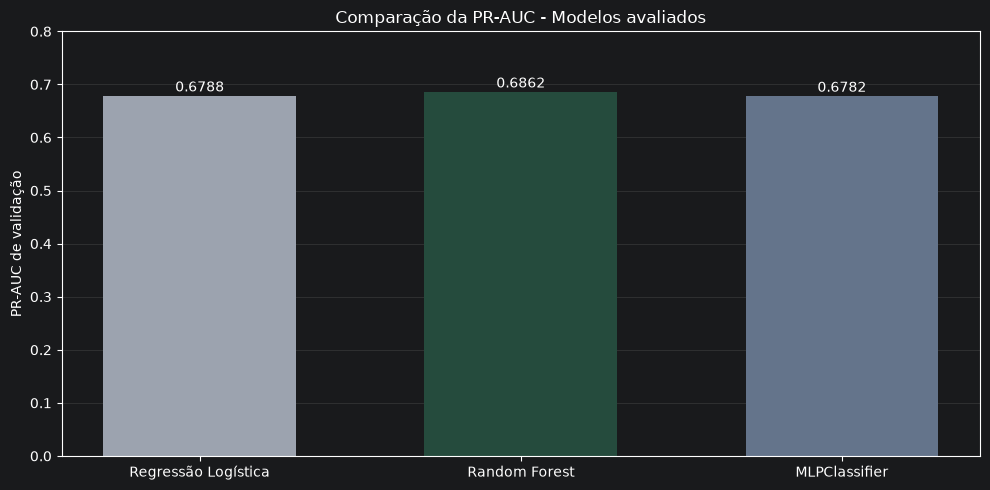

In [30]:
# Célula 30 - Gráfico comparativo dos três modelos

# Recupera a PR-AUC de validação
valores_finais = comparacao_final.loc["PR-AUC"]

cores_finais = ["#9CA3AF", "#254B3D", "#64748B"]

fig, ax = plt.subplots(figsize=(10, 5))

barras = ax.bar(
    valores_finais.index,
    valores_finais.values,
    color=cores_finais,
    width=0.6
)

# Exibe os resultados acima das barras
for barra, valor in zip(barras, valores_finais.values):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.008,
        f"{valor:.4f}",
        ha="center",
        fontsize=10
    )

ax.set_title("Comparação da PR-AUC - Modelos avaliados")
ax.set_ylabel("PR-AUC de validação")
ax.set_ylim(0, 0.8)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### Escolha do modelo campeão

Depois de comparar a Regressão Logística, a Random Forest e o MLPClassifier, vamos escolher a Random Forest otimizada pelo GridSearchCV como nosso modelo campeão.
Ela apresentou a maior PR-AUC de validação (0,6862) e também a maior ROC-AUC (0,8627). Como definimos a PR-AUC como nossa métrica principal, vamos seguir com essa configuração para a avaliação final.

A diferença entre os modelos foi pequena. A Regressão Logística apresentou Recall (0,8094) e F1 (0,6398) superiores, o que também precisa ser considerado, principalmente se o objetivo for identificar o maior número possível de clientes com risco de churn.

Nossa escolha prioriza a PR-AUC, mas não significa que a Random Forest seja superior em todas as métricas. Até aqui, utilizamos apenas os resultados da validação cruzada para selecionar o modelo.

Também precisamos considerar que utilizamos os mesmos cinco folds para buscar os melhores hiperparâmetros e depois comparar os modelos selecionados. Por isso, essa comparação não representa uma validação independente das buscas e os resultados podem estar um pouco otimistas. Dessa forma, não podemos afirmar que a Random Forest seja estatisticamente superior aos demais modelos.

O próximo passo será avaliar a configuração escolhida no conjunto de teste, que mantivemos separado durante os experimentos da Etapa 2.


In [31]:
# Célula 31 - Avaliação final do modelo campeão

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score
)

# Recupera o pipeline selecionado na validação cruzada
modelo_campeao = grid_rf.best_estimator_

# Realiza previsões no conjunto de teste
probabilidades_teste = modelo_campeao.predict_proba(X_test)[:, 1]
previsoes_teste = modelo_campeao.predict(X_test)

# Calcula as métricas no teste
metricas_teste = {
    "PR-AUC": average_precision_score(y_test, probabilidades_teste),
    "ROC-AUC": roc_auc_score(y_test, probabilidades_teste),
    "Recall": recall_score(y_test, previsoes_teste),
    "Precision": precision_score(y_test, previsoes_teste),
    "F1": f1_score(y_test, previsoes_teste)
}

# Recupera as métricas médias de validação da melhor Random Forest
metricas_validacao = {
    "PR-AUC": resultados_grid_completo["test_pr_auc"].mean(),
    "ROC-AUC": resultados_grid_completo["test_roc_auc"].mean(),
    "Recall": resultados_grid_completo["test_recall"].mean(),
    "Precision": resultados_grid_completo["test_precision"].mean(),
    "F1": resultados_grid_completo["test_f1"].mean()
}

# Organiza a comparação final
tabela_final_modelo = pd.DataFrame({
    "Métrica": list(metricas_teste.keys()),
    "Validação cruzada": [metricas_validacao[m] for m in metricas_teste.keys()],
    "Resultado no teste": [metricas_teste[m] for m in metricas_teste.keys()],
    "Diferença": [
        metricas_teste[m] - metricas_validacao[m]
        for m in metricas_teste.keys()
    ]
})

display(
    tabela_final_modelo.style
    .format({
        "Validação cruzada": "{:.4f}",
        "Resultado no teste": "{:.4f}",
        "Diferença": "{:+.4f}"
    })
    .hide(axis="index")
    .set_properties(**{
        "padding": "9px 14px",
        "border-bottom": "1px solid #555",
        "text-align": "center"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("padding", "10px 14px"),
                ("border-bottom", "2px solid #777")
            ]
        }
    ])
)

Métrica,Validação cruzada,Resultado no teste,Diferença
PR-AUC,0.6862,0.6656,-0.0206
ROC-AUC,0.8627,0.8537,-0.0091
Recall,0.5445,0.5455,+0.0010
Precision,0.6746,0.6645,-0.0101
F1,0.6022,0.5991,-0.0030



### Resultado final do modelo campeão

Depois de escolher a Random Forest pelo resultado da validação cruzada, avaliamos o pipeline no conjunto de teste que mantivemos separado durante os experimentos da Etapa 2.

Obtivemos PR-AUC de 0,6656 e ROC-AUC de 0,8537. O Recall foi de 0,5455, a Precision de 0,6645 e o F1 de 0,5991.

A PR-AUC no teste ficou um pouco abaixo da validação cruzada (0,6862), mas as demais métricas apresentaram resultados próximos. Isso indica que o modelo manteve um desempenho relativamente consistente nos dados que não utilizamos para ajustar os modelos nesta etapa.

Precisamos considerar que esse conjunto de teste já havia sido utilizado na avaliação do baseline da Etapa 1. Embora não tenha sido usado para ajustar os modelos na Etapa 2, ele não era completamente inédito no projeto. Por isso, os resultados devem ser interpretados considerando essa limitação.

Outra limitação importante é o Recall de 0,5455, pois o modelo deixou de identificar parte dos clientes que realmente apresentaram churn. A Regressão Logística também apresentou Recall superior na validação cruzada.

Vamos manter a Random Forest como modelo campeão porque apresentou a maior PR-AUC média na validação cruzada, conforme o critério que definimos. Porém, a diferença entre os modelos foi pequena e não podemos afirmar que ela seja superior em todas as situações.


In [32]:
# Célula 32 - Salvamento do modelo campeão

from pathlib import Path
import joblib

# Localiza a raiz do projeto
raiz_projeto = Path.cwd()
if raiz_projeto.name == "notebooks":
    raiz_projeto = raiz_projeto.parent

# Define o caminho do arquivo
pasta_modelos = raiz_projeto / "models"
pasta_modelos.mkdir(parents=True, exist_ok=True)

caminho_modelo = pasta_modelos / "pipeline_churn_rf.joblib"

# Salva o pipeline completo
joblib.dump(modelo_campeao, caminho_modelo)

print(f"Pipeline salvo em: {caminho_modelo}")
print(f"Tamanho do arquivo: {caminho_modelo.stat().st_size / 1024:.2f} KB")

Pipeline salvo em: F:\FIAP_MLE\Phase_1\techChallenge\models\pipeline_churn_rf.joblib
Tamanho do arquivo: 829.51 KB


In [33]:
# Célula 33 - Verificação do pipeline salvo

# Carrega o pipeline diretamente do arquivo
modelo_carregado = joblib.load(caminho_modelo)

# Compara as probabilidades antes e depois do salvamento
probabilidades_carregadas = modelo_carregado.predict_proba(X_test)[:, 1]

diferenca_maxima = np.max(
    np.abs(probabilidades_teste - probabilidades_carregadas)
)

# Verifica se as previsões foram preservadas
previsoes_iguais = np.array_equal(
    previsoes_teste,
    modelo_carregado.predict(X_test)
)

print(f"Pipeline carregado: {type(modelo_carregado).__name__}")
print(f"Diferença máxima nas probabilidades: {diferenca_maxima:.10f}")
print(f"Classificações idênticas: {previsoes_iguais}")

assert np.allclose(probabilidades_teste, probabilidades_carregadas)
assert previsoes_iguais

Pipeline carregado: Pipeline
Diferença máxima nas probabilidades: 0.0000000000
Classificações idênticas: True



### Salvamento e verificação do modelo

Depois da avaliação final, salvamos o pipeline campeão no arquivo `models/pipeline_churn_rf.joblib`, incluindo o pré-processamento e a Random Forest.

Para verificar o arquivo, carregamos o pipeline com joblib e comparamos suas previsões com as do modelo original. A diferença máxima entre as probabilidades foi zero e todas as classificações foram idênticas.

Com isso, confirmamos que o arquivo preservou as previsões e poderá ser utilizado na próxima etapa, em que vamos desenvolver a API com FastAPI.
